# Face verification: classification vs triplet
Thuận Minh · Hawkeye · Local GPU · Cosine / Euclidean · Kaggle validation pairs

This notebook contains all project-specific evaluation code. It uses the two frozen inference exports from notebook 02. It does not train either model or change the source exports.

**Protocol fixed before scoring:** known pixel overlap with the classification train/validation/test data and inferred same-person components is excluded from the independent calibration/holdout protocol. Positive-pair links and duplicate pixels form groups. A deterministic 50/50 hash split assigns complete groups; cross-split negative comparisons are excluded. Calibration chooses the model and operating threshold; holdout is evaluated only after that decision is saved.

Full-file ROC/AUC on all 8,805 pairs is also reported to satisfy the project specification, but is descriptive rather than the independent holdout estimate. Positive-link grouping does not prove complete identity separation because full identity metadata is unavailable. Only six distinct first-image anchors supply all negative comparisons, limiting population-level conclusions.

The primary operating policy is an **experimental empirical calibration FAR budget of 1%**, not a deployment guarantee. Additional 0.1% and maximum-balanced-accuracy calibration policies show the trade-off. AUC is ranking quality, not identification accuracy or a guarantee of attendance performance.


In [1]:
from pathlib import Path, PurePosixPath
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
import csv, json, hashlib, os, time, math, platform, shutil
from contextlib import contextmanager
import numpy as np
from PIL import Image
import torch
from torch import nn
from torch.nn import functional as F
import torchvision
from torchvision.models import resnet18
import sklearn
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ml/face_recognition").is_dir())
AUDIT_PATH = ROOT / "data/raw/face_recognition/audit/dataset_report.json"
EXPORTS_PATH = ROOT / "runs/face_recognition/triplet_optimization_v1/exports.json"
STUDY_ROOT = ROOT / "runs/face_recognition/verification_fp32_v1"
STUDY_ROOT.mkdir(parents=True, exist_ok=True)
SEED = 53
TARGET_FAR = 0.01
BATCH_SIZE = 256
assert torch.cuda.is_available(), "Select the local CUDA-enabled Python kernel."
torch.set_num_threads(4)
torch.backends.cudnn.benchmark = True
# Require full float32 convolution precision, including across different batch sizes.
torch.backends.cudnn.allow_tf32 = False
torch.backends.cuda.matmul.allow_tf32 = False
print("GPU", torch.cuda.get_device_name(0))
print("Python / torch / torchvision / sklearn", platform.python_version(), torch.__version__, torchvision.__version__, sklearn.__version__)

GPU NVIDIA GeForce RTX 4060 Laptop GPU
Python / torch / torchvision / sklearn 3.13.7 2.6.0+cu124 0.21.0+cu124 1.8.0


In [2]:
def file_sha256(path):
    checksum = hashlib.sha256()
    with path.open("rb") as source:
        for chunk in iter(lambda: source.read(1024 * 1024), b""):
            checksum.update(chunk)
    return checksum.hexdigest()

def write_json(path, value):
    temporary = path.with_name(path.name + f".{os.getpid()}.tmp")
    temporary.write_text(json.dumps(value, indent=2, allow_nan=False) + "\n", encoding="utf-8")
    os.replace(temporary, path)

def save_checkpoint(path, value):
    temporary = path.with_name(path.name + f".{os.getpid()}.tmp")
    with temporary.open("wb") as stream:
        torch.save(value, stream)
        stream.flush()
        os.fsync(stream.fileno())
    os.replace(temporary, path)

@contextmanager
def run_lock(directory):
    with (directory / ".training.lock").open("a+b") as lock:
        lock.write(b"1")
        lock.flush()
        lock.seek(0)
        try:
            if os.name == "nt":
                import msvcrt
                msvcrt.locking(lock.fileno(), msvcrt.LK_NBLCK, 1)
            else:
                import fcntl
                fcntl.flock(lock.fileno(), fcntl.LOCK_EX | fcntl.LOCK_NB)
        except OSError as error:
            raise RuntimeError("Another process is using this training directory") from error
        yield

class FaceEmbedding(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = resnet18(weights=None)
        self.backbone.fc = nn.Identity()

    def forward(self, images):
        return F.normalize(self.backbone(images).float(), dim=1)

## Parse, audit and split before inference

Every image path is checked against the audited manifest. The model-training pixels must have no overlap with these verification images. Known classification-validation/test pixel overlap and its observed positive-link components are removed from the independent protocol. Both image paths and pixel fingerprints are disjoint between the retained calibration and holdout sets.

A split is based only on source paths/pixels and pair labels, never embeddings or measured quality. Labels are 1 for same-person and 0 for different-person. No negative pair may contradict its positive-link component.


In [3]:
audit = json.loads(AUDIT_PATH.read_text(encoding="utf-8"))
assert audit["checks_passed"]
DATASET_ROOT = Path(audit["dataset_root"])
PAIR_PATH = DATASET_ROOT / "verification_pairs_val.txt"
assert file_sha256(Path(audit["manifest"])) == audit["manifest_sha256"]
pairs = []
for number, line in enumerate(PAIR_PATH.read_text(encoding="utf-8-sig").splitlines(), 1):
    if not line.strip():
        continue
    fields = line.split()
    assert len(fields) == 3 and fields[2] in {"0", "1"}, number
    for name in fields[:2]:
        relative = PurePosixPath(name)
        assert not relative.is_absolute() and ".." not in relative.parts and "\\" not in name and ":" not in name
        assert (DATASET_ROOT / name).resolve().is_relative_to(DATASET_ROOT.resolve())
        assert (DATASET_ROOT / name).is_file()
    pairs.append((fields[0], fields[1], int(fields[2])))
assert len(pairs) == 8805 and Counter(p[2] for p in pairs) == {0:4490, 1:4315}
assert len({tuple(sorted(p[:2])) for p in pairs}) == len(pairs)
image_names = sorted({name for p in pairs for name in p[:2]})
name_index = {name:i for i,name in enumerate(image_names)}
pair_first = np.array([name_index[p[0]] for p in pairs])
pair_second = np.array([name_index[p[1]] for p in pairs])
labels = np.array([p[2] for p in pairs], dtype=np.int64)
manifest_rows = {}
train_pixels, selection_pixels = set(), set()
with Path(audit["manifest"]).open(encoding="utf-8", newline="") as stream:
    for row in csv.DictReader(stream):
        if row["path"] in name_index:
            manifest_rows[row["path"]] = row
        if row["train_eligible"] == "1":
            train_pixels.add(row["pixel_sha256"])
        elif row["split"] in {"val_data", "test_data"}:
            selection_pixels.add(row["pixel_sha256"])
assert len(manifest_rows) == len(image_names)
referenced_pixels = {name:manifest_rows[name]["pixel_sha256"] for name in image_names}
training_overlap = {n for n in image_names if referenced_pixels[n] in train_pixels}
assert not training_overlap, "Training/verification pixel leakage must be resolved before evaluation."

parent = {name:name for name in image_names}
def find(name):
    while parent[name] != name:
        parent[name] = parent[parent[name]]
        name = parent[name]
    return name

def union(first, second):
    first, second = find(first), find(second)
    if first != second:
        parent[max(first, second)] = min(first, second)

first_by_pixel = {}
for name in image_names:
    pixel = referenced_pixels[name]
    if pixel in first_by_pixel:
        union(name, first_by_pixel[pixel])
    else:
        first_by_pixel[pixel] = name
for first, second, label in pairs:
    if label == 1:
        union(first, second)
assert all(find(a) != find(b) for a,b,y in pairs if y == 0)
groups = {name:find(name) for name in image_names}
known_overlap = {name for name in image_names if referenced_pixels[name] in selection_pixels}
excluded_groups = {groups[name] for name in known_overlap}
assignment = {
    group: int(hashlib.sha256(f"{SEED}:{group}".encode()).hexdigest(), 16) % 100 < 50
    for group in sorted(set(groups.values()))
}
# 0=known-overlap exclusion, 1=calibration, 2=holdout, 3=cross-split exclusion.
roles = []
for first, second, label in pairs:
    a,b = groups[first], groups[second]
    if a in excluded_groups or b in excluded_groups:
        roles.append(0)
    elif assignment[a] != assignment[b]:
        roles.append(3)
    else:
        roles.append(1 if assignment[a] else 2)
roles = np.asarray(roles, dtype=np.int64)
calibration_mask, holdout_mask = roles == 1, roles == 2
def role_images(mask):
    return {name for i,pair in enumerate(pairs) if mask[i] for name in pair[:2]}
cal_images, hold_images = role_images(calibration_mask), role_images(holdout_mask)
assert not cal_images & hold_images
assert not {referenced_pixels[n] for n in cal_images} & {referenced_pixels[n] for n in hold_images}
assert not {groups[n] for n in cal_images} & {groups[n] for n in hold_images}
for mask in [calibration_mask, holdout_mask]:
    assert min(Counter(labels[mask]).values()) >= 100

exports = json.loads(EXPORTS_PATH.read_text())
assert {row["model"] for row in exports} == {"classification", "triplet"}
model_inputs = {}
for row in exports:
    path = Path(row["path"])
    assert file_sha256(path) == row["sha256"]
    model_inputs[row["model"]] = {"path":str(path), "sha256":row["sha256"]}
protocol = {
    "seed":SEED, "target_calibration_far":TARGET_FAR, "inference_precision":"float32_tf32_disabled", "pairs_sha256":file_sha256(PAIR_PATH),
    "manifest_sha256":audit["manifest_sha256"], "model_inputs":model_inputs,
    "roles":roles.tolist(), "known_overlap_images":len(known_overlap),
    "pair_counts":{name:dict(Counter(labels[roles == code].tolist())) for name,code in [
        ("known_overlap_excluded",0),("calibration",1),("holdout",2),("cross_split_excluded",3)]},
    "full_negative_anchor_count":len({a for a,b,y in pairs if y == 0}),
    "identity_separation":"Observed positive components only; complete identity metadata unavailable.",
}
protocol_path = STUDY_ROOT / "protocol.json"
if protocol_path.is_file():
    assert json.loads(protocol_path.read_text()) == json.loads(json.dumps(protocol)), "Use a new study directory for changed inputs/protocol."
else:
    write_json(protocol_path, protocol)
PROTOCOL_SHA256 = file_sha256(protocol_path)
print(json.dumps({k:v for k,v in protocol.items() if k not in {"roles","model_inputs"}}, indent=2))

{
  "seed": 53,
  "target_calibration_far": 0.01,
  "inference_precision": "float32_tf32_disabled",
  "pairs_sha256": "55ecf1495188024f414e3b0faac2b7f4cc374000a809e3b98579ecd8f4f25fdd",
  "manifest_sha256": "fe1e0cdf8362c121aed4a4c32759fa198ac19e43996ad44174ae3de27ecf328f",
  "known_overlap_images": 53,
  "pair_counts": {
    "known_overlap_excluded": {
      "0": 33,
      "1": 46
    },
    "calibration": {
      "1": 2112,
      "0": 1025
    },
    "holdout": {
      "0": 1157,
      "1": 2157
    },
    "cross_split_excluded": {
      "0": 2275
    }
  },
  "full_negative_anchor_count": 6,
  "identity_separation": "Observed positive components only; complete identity metadata unavailable."
}


## Verified RGB cache and frozen embeddings

Decode only the 9,355 images referenced by the pairs. Each decoded RGB image must match its audited pixel fingerprint. Cache and embedding files are fingerprinted. Inference uses float32 and the export's exact RGB, pixel scaling, resize and normalization contract.

Both models return unit 512-dimensional embeddings. Float64 renormalization before pair scoring makes the identity d² = 2 - 2 cosine explicit; direct Euclidean distance is checked independently. This explains why cosine and Euclidean ROC/AUC should agree for each normalized model.


TF32 is explicitly disabled for convolution and matrix multiplication. A numerical preflight observed approximately 1.7e-4 element differences with TF32 enabled, while full-float32 inference reproduced embeddings across batch sizes. The final experiment uses a new fingerprinted run directory and the same predeclared split/selection rules.

In [4]:
def decode_verified(name):
    with Image.open(DATASET_ROOT / name) as image:
        image.load()
        image = image.convert("RGB")
        assert image.size == (64,64), name
        raw = image.tobytes()
        assert hashlib.sha256(b"64x64:RGB:" + raw).hexdigest() == referenced_pixels[name], name
        return np.asarray(image).copy()

cache_path = STUDY_ROOT / "referenced_rgb.npy"
cache_meta_path = STUDY_ROOT / "referenced_rgb.json"
if cache_meta_path.is_file():
    cache_meta = json.loads(cache_meta_path.read_text())
    assert cache_meta["protocol_sha256"] == PROTOCOL_SHA256
    assert file_sha256(cache_path) == cache_meta["sha256"]
else:
    with ThreadPoolExecutor(max_workers=8) as executor:
        rgb = np.stack(list(executor.map(decode_verified, image_names)))
    temporary = cache_path.with_suffix(".building.npy")
    np.save(temporary, rgb)
    os.replace(temporary, cache_path)
    cache_meta = {"protocol_sha256":PROTOCOL_SHA256, "sha256":file_sha256(cache_path), "images":len(image_names)}
    write_json(cache_meta_path, cache_meta)
    del rgb
rgb_cache = np.load(cache_path, mmap_mode="r")
assert rgb_cache.shape == (9355,64,64,3) and rgb_cache.dtype == np.uint8

def extract_embeddings(name, info):
    output = STUDY_ROOT / f"{name}_embeddings.npy"
    metadata_path = STUDY_ROOT / f"{name}_embeddings.json"
    if metadata_path.is_file():
        metadata = json.loads(metadata_path.read_text())
        assert metadata["model_sha256"] == info["sha256"] and metadata["rgb_sha256"] == cache_meta["sha256"]
        assert file_sha256(output) == metadata["sha256"]
        return np.load(output)
    payload = torch.load(info["path"], map_location="cpu", weights_only=True)
    assert payload["architecture"] == "resnet18_embedding" and payload["embedding_dimensions"] == 512
    assert payload["manifest_sha256"] == audit["manifest_sha256"]
    assert payload["color_space"] == "RGB" and payload["pixel_scale"] == 1/255
    assert payload["resize"] == {"mode":"bilinear","align_corners":False,"antialias":True}
    model = FaceEmbedding().to("cuda", memory_format=torch.channels_last).eval()
    model.load_state_dict(payload["state_dict"], strict=True)
    mean = torch.tensor(payload["normalization"]["mean"], device="cuda").view(1,3,1,1)
    std = torch.tensor(payload["normalization"]["std"], device="cuda").view(1,3,1,1)
    result = []
    with torch.inference_mode():
        for start in range(0,len(rgb_cache),BATCH_SIZE):
            raw = torch.from_numpy(np.array(rgb_cache[start:start+BATCH_SIZE],copy=True)).pin_memory().to("cuda",non_blocking=True)
            x = raw.permute(0,3,1,2).float().div_(255)
            x = F.interpolate(x,size=payload["input_size"],mode="bilinear",align_corners=False,antialias=True)
            x = ((x-mean)/std).contiguous(memory_format=torch.channels_last)
            z = model(x)
            assert torch.isfinite(z).all() and z.shape[1] == 512
            assert torch.allclose(z.norm(dim=1),torch.ones(len(z),device="cuda"),atol=1e-5)
            result.append(z.cpu().numpy())
    embeddings = np.concatenate(result)
    np.save(output, embeddings)
    write_json(metadata_path, {"model_sha256":info["sha256"], "rgb_sha256":cache_meta["sha256"],
                              "sha256":file_sha256(output),"images":len(embeddings)})
    del model,payload,mean,std,x,z,raw
    torch.cuda.empty_cache()
    return embeddings

scores = {}
for name, info in model_inputs.items():
    embeddings = extract_embeddings(name,info).astype(np.float64)
    assert embeddings.shape == (len(image_names),512)
    embeddings /= np.linalg.norm(embeddings,axis=1,keepdims=True)
    first,second = embeddings[pair_first],embeddings[pair_second]
    cosine = np.clip(np.sum(first*second,axis=1),-1,1)
    euclidean = np.sqrt(np.maximum(2-2*cosine,0))
    direct_distance = np.linalg.norm(first-second,axis=1)
    assert np.allclose(euclidean,direct_distance,atol=1e-12,rtol=1e-12)
    scores[name] = {"cosine":cosine,"euclidean":euclidean}
    print(name,"verified embeddings",embeddings.shape)
np.savez_compressed(STUDY_ROOT/"pair_scores.npz", labels=labels, roles=roles,
                    **{f"{name}_{metric}":values for name,row in scores.items() for metric,values in row.items()})

classification verified embeddings (9355, 512)


triplet verified embeddings (9355, 512)


## Calibration only: freeze model and thresholds

The main policy maximizes calibration TAR subject to empirical FAR <= 1%. Ties prefer lower FAR, then the stricter threshold. Among the two models, calibration TAR selects the model; calibration AUC breaks ties. Cosine is the selected representation because normalized Euclidean is an equivalent monotonic transformation, not because one has a higher measured AUC.

The threshold is placed between adjacent calibration scores where possible to avoid numerical boundary ambiguity. Two predefined sensitivity policies (FAR <= 0.1% and maximum balanced accuracy) are also frozen now. Holdout labels/scores are not consulted by these decisions.


In [5]:
def cosine_to_distance_threshold(threshold):
    if threshold > 1:
        return -1.0
    if threshold < -1:
        return 2.0 + 1e-12
    return float(np.sqrt(max(2-2*threshold,0)))

def decisions(name, metric, threshold):
    values = scores[name][metric]
    return values >= threshold if metric == "cosine" else values <= threshold

def error_metrics(y, predicted):
    tn,fp,fn,tp = (int(x) for x in confusion_matrix(y,predicted,labels=[0,1]).ravel())
    assert tp+fn > 0 and fp+tn > 0
    far, frr = fp/(fp+tn),fn/(tp+fn)
    return {"pairs":len(y),"positive_pairs":tp+fn,"negative_pairs":fp+tn,
            "true_positive":tp,"false_positive":fp,"true_negative":tn,"false_negative":fn,
            "far":far,"frr":frr,"tar":1-frr,"accuracy":(tp+tn)/len(y),
            "balanced_accuracy":((1-frr)+(1-far))/2}

def calibrated_threshold(name, policy, far_budget=None):
    y,values = labels[calibration_mask],scores[name]["cosine"][calibration_mask]
    fpr,tpr,thresholds = roc_curve(y,values,drop_intermediate=False)
    if policy == "far_budget":
        eligible = np.flatnonzero(fpr <= far_budget + 1e-12)
        index = max(eligible,key=lambda i:(tpr[i],-fpr[i],thresholds[i]))
    elif policy == "balanced_accuracy":
        index = max(range(len(fpr)),key=lambda i:(tpr[i]-fpr[i],-fpr[i],thresholds[i]))
    else:
        raise ValueError(policy)
    raw_threshold = thresholds[index]
    if not np.isfinite(raw_threshold):
        threshold = 1.0 + 1e-12
    else:
        lower = np.unique(values[values < raw_threshold])
        threshold = float((raw_threshold + lower[-1])/2) if len(lower) else -1.0
    metric = error_metrics(y,decisions(name,"cosine",threshold)[calibration_mask])
    if policy == "far_budget":
        assert metric["far"] <= far_budget + 1e-12
    distance_threshold = cosine_to_distance_threshold(threshold)
    assert np.array_equal(decisions(name,"cosine",threshold), decisions(name,"euclidean",distance_threshold))
    return {"policy":policy,"calibration_far_budget":far_budget,
            "cosine_threshold":threshold,"euclidean_threshold":distance_threshold,
            "calibration_metrics":metric,
            "calibration_auc":float(roc_auc_score(y,values))}

calibration_results = {name:calibrated_threshold(name,"far_budget",TARGET_FAR) for name in model_inputs}
model_order = list(model_inputs)
selected_name = max(model_order,key=lambda name:(
    calibration_results[name]["calibration_metrics"]["tar"],
    calibration_results[name]["calibration_auc"],-model_order.index(name)))
sensitivity_policies = {
    "far_0.1_percent":calibrated_threshold(selected_name,"far_budget",0.001),
    "far_1_percent":calibration_results[selected_name],
    "balanced_accuracy":calibrated_threshold(selected_name,"balanced_accuracy"),
}
selection = {
    "protocol_sha256":PROTOCOL_SHA256,"selected_model":selected_name,"selected_metric":"cosine",
    "selection_rule":"Calibration TAR at empirical FAR <= 1%, then calibration AUC; model order breaks exact ties.",
    "metric_choice_reason":"L2 normalization makes cosine and Euclidean rankings equivalent; cosine uses the native similarity contract.",
    "calibration_results":calibration_results,"sensitivity_policies":sensitivity_policies,
    "threshold":calibration_results[selected_name]["cosine_threshold"],"comparison":">=",
    "equivalent_euclidean_threshold":calibration_results[selected_name]["euclidean_threshold"],
    "euclidean_comparison":"<=",
}
selection_path = STUDY_ROOT / "selection.json"
with run_lock(STUDY_ROOT):
    if selection_path.is_file():
        assert json.loads(selection_path.read_text()) == selection
    else:
        write_json(selection_path,selection)
print(json.dumps(selection,indent=2))

{
  "protocol_sha256": "ae0aa734753cd045e357f6696b283cdd899cc21c7fdd33c51e2e1e9f0e93c983",
  "selected_model": "triplet",
  "selected_metric": "cosine",
  "selection_rule": "Calibration TAR at empirical FAR <= 1%, then calibration AUC; model order breaks exact ties.",
  "metric_choice_reason": "L2 normalization makes cosine and Euclidean rankings equivalent; cosine uses the native similarity contract.",
  "calibration_results": {
    "classification": {
      "policy": "far_budget",
      "calibration_far_budget": 0.01,
      "cosine_threshold": 0.5689842216641936,
      "euclidean_threshold": 0.9284565453868118,
      "calibration_metrics": {
        "pairs": 3137,
        "positive_pairs": 2112,
        "negative_pairs": 1025,
        "true_positive": 558,
        "false_positive": 10,
        "true_negative": 1015,
        "false_negative": 1554,
        "far": 0.00975609756097561,
        "frr": 0.7357954545454546,
        "tar": 0.2642045454545454,
        "accuracy": 0.5014344915

## Independent holdout and complete-file ROC/AUC

The selection above is frozen before this cell. Report all four combinations on full pairs and independently retained holdout pairs. Full-file AUC reuses calibration comparisons and known selection-overlap images, so it is descriptive. Holdout FAR is measured, not guaranteed to stay below the calibration budget.

Negative comparisons share only six first-image anchors across the full file. Pair counts therefore overstate independent negative-face diversity. The notebook reports anchor-level FAR and does not attach an unjustified independent-pair confidence interval.


In [6]:
def ranking_metrics(y,values):
    fpr,tpr,thresholds = roc_curve(y,values,drop_intermediate=False)
    index = int(np.argmin(np.abs(fpr-(1-tpr))))
    return {"auc":float(roc_auc_score(y,values)),
            "eer_approx":float((fpr[index]+1-tpr[index])/2)}

results = []
for name in model_inputs:
    policy = calibration_results[name]
    for metric in ["cosine","euclidean"]:
        threshold = policy[f"{metric}_threshold"]
        predicted = decisions(name,metric,threshold)
        rank_scores = scores[name][metric] if metric == "cosine" else -scores[name][metric]
        row = {"model":name,"metric":metric,"threshold":threshold,
               "comparison":">=" if metric=="cosine" else "<=",
               "full_ranking":ranking_metrics(labels,rank_scores),
               "calibration":{**error_metrics(labels[calibration_mask],predicted[calibration_mask]),
                              **ranking_metrics(labels[calibration_mask],rank_scores[calibration_mask])},
               "holdout":{**error_metrics(labels[holdout_mask],predicted[holdout_mask]),
                          **ranking_metrics(labels[holdout_mask],rank_scores[holdout_mask])}}
        results.append(row)
    assert abs(results[-1]["full_ranking"]["auc"]-results[-2]["full_ranking"]["auc"]) < 1e-12
    assert abs(results[-1]["holdout"]["auc"]-results[-2]["holdout"]["auc"]) < 1e-12
    for key in ["true_positive","false_positive","true_negative","false_negative"]:
        assert results[-1]["holdout"][key] == results[-2]["holdout"][key]
selected_result = next(row for row in results if row["model"]==selected_name and row["metric"]=="cosine")
sensitivity_results = {}
for policy_name,policy in sensitivity_policies.items():
    predicted = decisions(selected_name,"cosine",policy["cosine_threshold"])
    sensitivity_results[policy_name] = {
        **policy, "holdout_metrics":error_metrics(labels[holdout_mask],predicted[holdout_mask])}

anchor_rows = []
for anchor,count in Counter(a for a,b,y in pairs if y == 0).most_common():
    mask = np.array([a==anchor and y==0 for a,b,y in pairs])
    predicted = decisions(selected_name,"cosine",selection["threshold"])
    for role_name,role_mask in [("full",np.ones(len(pairs),dtype=bool)),("calibration",calibration_mask),("holdout",holdout_mask)]:
        subset = mask & role_mask
        if subset.any():
            anchor_rows.append({"anchor":anchor,"split":role_name,"negative_pairs":int(subset.sum()),
                                "false_matches":int(predicted[subset].sum()),"far":float(predicted[subset].mean())})

report = {
    "status":"evaluated_pending_export","protocol_sha256":PROTOCOL_SHA256,"pairs_sha256":protocol["pairs_sha256"],
    "manifest_sha256":protocol["manifest_sha256"],"selection":selection,"results":results,
    "sensitivity_results":sensitivity_results,"negative_anchor_results":anchor_rows,
    "split_counts":protocol["pair_counts"],"known_overlap_images":len(known_overlap),
    "negative_anchor_count":protocol["full_negative_anchor_count"],
    "environment":{"python":platform.python_version(),"torch":str(torch.__version__),
                   "torchvision":str(torchvision.__version__),"numpy":np.__version__,"sklearn":sklearn.__version__,
                   "gpu":torch.cuda.get_device_name(0),"precision":"float32 inference (TF32 disabled) / float64 pair scoring"},
    "limitations":[
        "Calibration/holdout are disjoint in referenced image paths, pixel hashes and observed positive components.",
        "Unseen-person identity separation is not established without complete identity metadata.",
        "Full-file ROC/AUC is descriptive and includes pairs excluded from the independent protocol.",
        "Only six distinct first-image anchors generate all 4,490 negative pairs; comparisons are dependent.",
        "The 1% calibration FAR budget is experimental and is not a deployment or holdout guarantee.",
        "Pair verification does not measure multi-student gallery identification, liveness or real camera performance.",
    ],
}
write_json(STUDY_ROOT/"report.json",report)
table = ["| Model | Metric | Full-file AUC | Holdout AUC | Frozen threshold | Holdout FAR | Holdout FRR |",
         "| --- | --- | --- | --- | --- | --- | --- |"]
for row in results:
    table.append(f"| {row['model']} | {row['metric']} | {row['full_ranking']['auc']:.6f} | {row['holdout']['auc']:.6f} | "
                 f"{row['comparison']} {row['threshold']:.8f} | {100*row['holdout']['far']:.3f}% | {100*row['holdout']['frr']:.3f}% |")
display(Markdown("\n".join(table)))
display(Markdown(f"**Calibration-selected model:** {selected_name}. "
                 f"Holdout TAR **{100*selected_result['holdout']['tar']:.2f}%**, "
                 f"FAR **{100*selected_result['holdout']['far']:.2f}%**, "
                 f"balanced accuracy **{100*selected_result['holdout']['balanced_accuracy']:.2f}%**. "
                 "The threshold was not adjusted after viewing holdout."))
print(json.dumps({"split_counts":protocol["pair_counts"],"selected_holdout":selected_result["holdout"],
                  "anchor_results":anchor_rows},indent=2))

| Model | Metric | Full-file AUC | Holdout AUC | Frozen threshold | Holdout FAR | Holdout FRR |
| --- | --- | --- | --- | --- | --- | --- |
| classification | cosine | 0.792364 | 0.808926 | >= 0.56898422 | 2.420% | 73.157% |
| classification | euclidean | 0.792364 | 0.808926 | <= 0.92845655 | 2.420% | 73.157% |
| triplet | cosine | 0.953673 | 0.954488 | >= 0.52535242 | 1.988% | 45.897% |
| triplet | euclidean | 0.953673 | 0.954488 | <= 0.97431779 | 1.988% | 45.897% |

**Calibration-selected model:** triplet. Holdout TAR **54.10%**, FAR **1.99%**, balanced accuracy **76.06%**. The threshold was not adjusted after viewing holdout.

{
  "split_counts": {
    "known_overlap_excluded": {
      "0": 33,
      "1": 46
    },
    "calibration": {
      "1": 2112,
      "0": 1025
    },
    "holdout": {
      "0": 1157,
      "1": 2157
    },
    "cross_split_excluded": {
      "0": 2275
    }
  },
  "selected_holdout": {
    "pairs": 3314,
    "positive_pairs": 2157,
    "negative_pairs": 1157,
    "true_positive": 1167,
    "false_positive": 23,
    "true_negative": 1134,
    "false_negative": 990,
    "far": 0.019878997407087293,
    "frr": 0.45897079276773295,
    "tar": 0.5410292072322671,
    "accuracy": 0.6943270971635486,
    "balanced_accuracy": 0.76057510491259,
    "auc": 0.9544875902019877,
    "eer_approx": 0.11227620550806627
  },
  "anchor_results": [
    {
      "anchor": "verification_data/00046783.jpg",
      "split": "full",
      "negative_pairs": 879,
      "false_matches": 29,
      "far": 0.03299203640500569
    },
    {
      "anchor": "verification_data/00046783.jpg",
      "split": "holdout",
 

## ROC, score distributions and threshold trade-offs

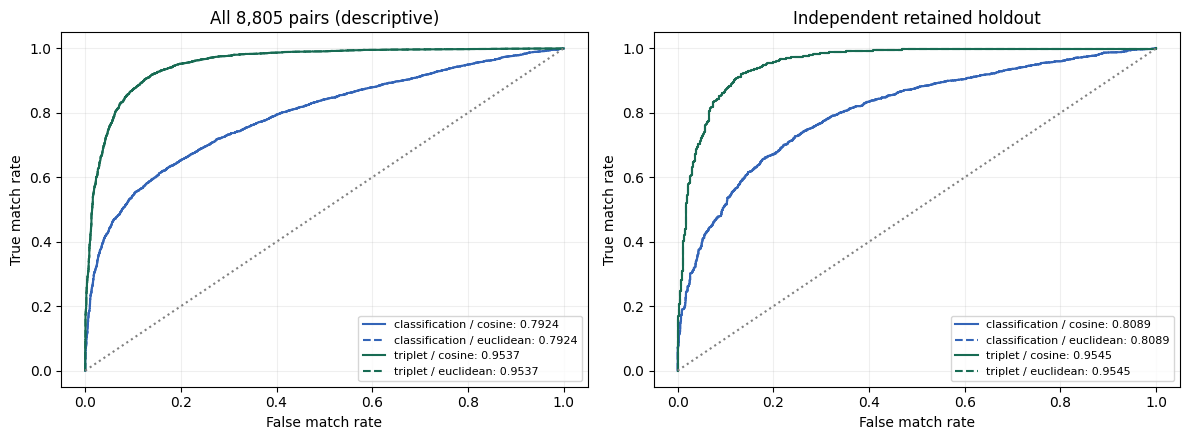

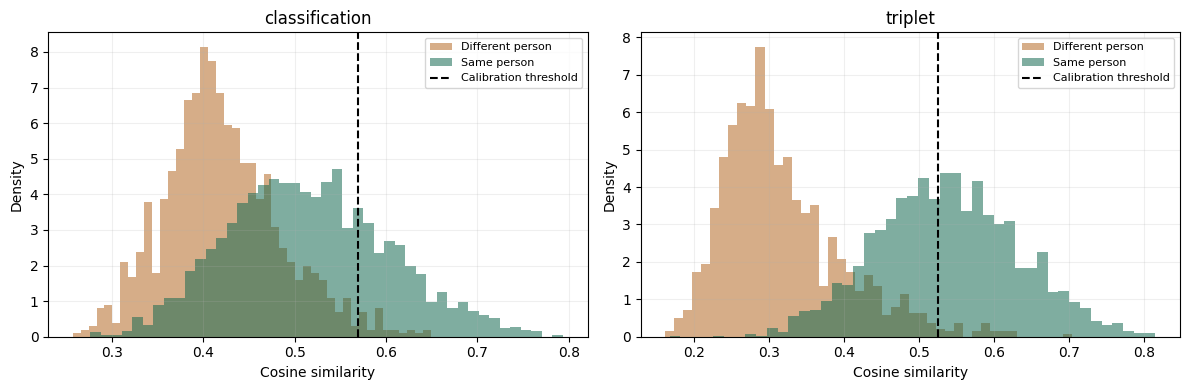

| Predefined calibration policy | Cosine threshold | Calibration FAR | Holdout FAR | Holdout TAR | Holdout balanced accuracy |
| --- | --- | --- | --- | --- | --- |
| far_0.1_percent | 0.59706573 | 0.098% | 0.605% | 25.730% | 62.563% |
| far_1_percent | 0.52535242 | 0.976% | 1.988% | 54.103% | 76.058% |
| balanced_accuracy | 0.41151550 | 13.073% | 12.705% | 91.099% | 89.197% |

Cosine and Euclidean curves overlap because unit embeddings make their rankings equivalent. These operating points were all defined on calibration, not optimized on holdout.

In [7]:
fig,axes = plt.subplots(1,2,figsize=(12,4.5))
for row in results:
    name,metric = row["model"],row["metric"]
    values = scores[name][metric] if metric=="cosine" else -scores[name][metric]
    color = "#3364b7" if name=="classification" else "#176b53"
    style = "-" if metric=="cosine" else "--"
    for axis,mask,split in [(axes[0],np.ones(len(labels),dtype=bool),"full_ranking"),(axes[1],holdout_mask,"holdout")]:
        fpr,tpr,_ = roc_curve(labels[mask],values[mask])
        axis.plot(fpr,tpr,style,color=color,label=f"{name} / {metric}: {row[split]['auc']:.4f}")
for axis,title in zip(axes,["All 8,805 pairs (descriptive)","Independent retained holdout"]):
    axis.plot([0,1],[0,1],":",color="gray")
    axis.set(xlabel="False match rate",ylabel="True match rate",title=title)
    axis.legend(fontsize=8);axis.grid(alpha=0.2)
fig.tight_layout();fig.savefig(STUDY_ROOT/"roc_curves.png",dpi=180,bbox_inches="tight");plt.show()

fig,axes = plt.subplots(1,2,figsize=(12,4))
for name,axis in zip(model_inputs,axes):
    values = scores[name]["cosine"]
    for label,color,title in [(0,"#b56b26","Different person"),(1,"#176b53","Same person")]:
        axis.hist(values[holdout_mask & (labels==label)],bins=45,alpha=.55,density=True,color=color,label=title)
    axis.axvline(calibration_results[name]["cosine_threshold"],linestyle="--",color="black",label="Calibration threshold")
    axis.set(xlabel="Cosine similarity",ylabel="Density",title=name)
    axis.legend(fontsize=8);axis.grid(alpha=.2)
fig.tight_layout();fig.savefig(STUDY_ROOT/"score_distributions.png",dpi=180,bbox_inches="tight");plt.show()

lines=["| Predefined calibration policy | Cosine threshold | Calibration FAR | Holdout FAR | Holdout TAR | Holdout balanced accuracy |",
       "| --- | --- | --- | --- | --- | --- |"]
for name,row in sensitivity_results.items():
    c,h=row["calibration_metrics"],row["holdout_metrics"]
    lines.append(f"| {name} | {row['cosine_threshold']:.8f} | {100*c['far']:.3f}% | {100*h['far']:.3f}% | "
                 f"{100*h['tar']:.3f}% | {100*h['balanced_accuracy']:.3f}% |")
display(Markdown("\n".join(lines)))
display(Markdown("Cosine and Euclidean curves overlap because unit embeddings make their rankings equivalent. "
                 "These operating points were all defined on calibration, not optimized on holdout."))

## Measured conclusion

**Triplet is the calibration-selected model**, with cosine threshold **>= 0.5253524211** (equivalent Euclidean **<= 0.9743177910**). This is a benchmark threshold, not a deployment acceptance guarantee.

On 3,314 independent retained holdout pairs, the frozen primary threshold produces:
- **AUC 0.954488**.
- **54.103% true-match acceptance**, with 990 false non-matches out of 2157 positive pairs.
- **1.988% false-match rate**, with 23 false matches out of 1157 negative pairs.

The predeclared balanced-accuracy policy accepts **91.099%** of true matches but also falsely accepts **12.705%** of different-person pairs. Thus a more permissive threshold does not make the model near-perfect.

These results show a substantial improvement over classification embeddings while **not supporting near-perfect attendance performance**. In addition to image/pose/camera variation and the limited model/training search, the benchmark itself has only six negative anchors. It cannot justify precise population-level false-match guarantees.

The full 8,805-pair AUC values satisfy the assignment's four-combination comparison. The smaller holdout estimate is kept separate from calibration and known classification-selection overlap. No thresholds were tuned on holdout after seeing these results. The numerical preflight was superseded by full-float32 inference using unchanged grouping and selection rules.


## Inspect the remaining errors

Examples below are the highest-scoring false matches and lowest-scoring false non-matches from the independent holdout, at the frozen calibration threshold. They illustrate residual score overlap; the dataset's supplied pair labels remain the reference. This display does not identify or name the people.


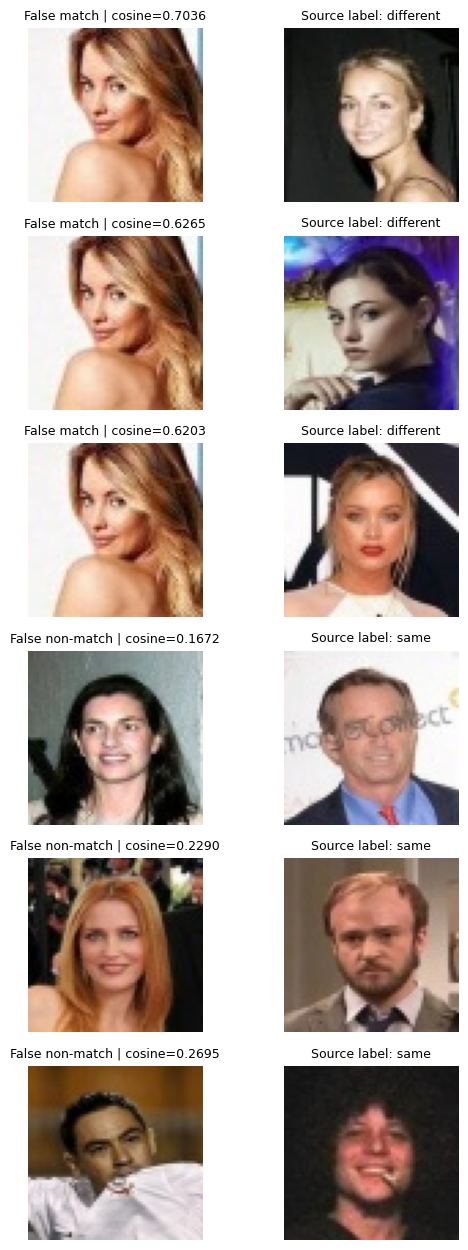

In [8]:
predicted = decisions(selected_name,"cosine",selection["threshold"])
false_matches = np.flatnonzero(holdout_mask & (labels==0) & predicted)
false_nonmatches = np.flatnonzero(holdout_mask & (labels==1) & ~predicted)
error_indices = [
    *sorted(false_matches,key=lambda i:-scores[selected_name]["cosine"][i])[:3],
    *sorted(false_nonmatches,key=lambda i:scores[selected_name]["cosine"][i])[:3],
]
if error_indices:
    fig,axes = plt.subplots(len(error_indices),2,figsize=(6,2.1*len(error_indices)),squeeze=False)
    for row,index in enumerate(error_indices):
        kind = "False match" if labels[index]==0 else "False non-match"
        for col,image_index in enumerate([pair_first[index],pair_second[index]]):
            axes[row,col].imshow(rgb_cache[image_index])
            axes[row,col].axis("off")
            axes[row,col].set_title(
                f"{kind} | cosine={scores[selected_name]['cosine'][index]:.4f}" if col==0
                else f"Source label: {'same' if labels[index] else 'different'}",fontsize=9)
    fig.tight_layout();fig.savefig(STUDY_ROOT/"holdout_error_examples.png",dpi=160,bbox_inches="tight");plt.show()
else:
    display(Markdown("No observed errors at this threshold in the retained holdout; this does not establish zero population error."))

## Export the calibration-selected model

The original classification/triplet exports remain unchanged. selected_model.pt is a separate inference artifact carrying the calibration-selected cosine threshold and its comparison direction. Its metadata labels the threshold as experimental and records the protocol fingerprint.

This is preparation for recognizer integration, not an update to the live backend. A new student gallery/camera setting still needs its own validation; comparing one pair is different from searching many registered students.


In [9]:
source_info = model_inputs[selected_name]
assert file_sha256(Path(source_info["path"])) == source_info["sha256"]
selected_payload = torch.load(source_info["path"],map_location="cpu",weights_only=True)
selected_payload["threshold"] = selection["threshold"]
selected_payload["metric"] = "cosine"
selected_payload["threshold_comparison"] = ">="
selected_payload["threshold_status"] = "Experimental calibration threshold; real gallery/camera validation required"
selected_payload["source_inference_sha256"] = source_info["sha256"]
selected_payload["inference_precision"] = {"dtype":"float32","cudnn_allow_tf32":False,"matmul_allow_tf32":False}
selected_payload["verification_calibration"] = {
    "protocol_sha256":PROTOCOL_SHA256,"pairs_sha256":protocol["pairs_sha256"],
    "split_seed":SEED,"target_calibration_far":TARGET_FAR,
    "calibration_metrics":calibration_results[selected_name]["calibration_metrics"],
    "holdout_metrics":selected_result["holdout"],
    "equivalent_euclidean_threshold":selection["equivalent_euclidean_threshold"],
    "euclidean_comparison":"<=",
    "negative_anchor_count":protocol["full_negative_anchor_count"],
}
export_path = STUDY_ROOT/"selected_model.pt"
save_checkpoint(export_path,selected_payload)
restored_payload = torch.load(export_path,map_location="cpu",weights_only=True)
assert restored_payload["threshold"] == selection["threshold"] and restored_payload["threshold_comparison"] == ">="
assert all(torch.equal(value,restored_payload["state_dict"][key]) for key,value in selected_payload["state_dict"].items())
restored = FaceEmbedding().to("cuda",memory_format=torch.channels_last).eval()
restored.load_state_dict(restored_payload["state_dict"],strict=True)
with torch.inference_mode():
    raw = torch.from_numpy(np.array(rgb_cache[:8],copy=True)).to("cuda")
    x = raw.permute(0,3,1,2).float()/255
    x = F.interpolate(x,size=restored_payload["input_size"],mode="bilinear",align_corners=False,antialias=True)
    mean = torch.tensor(restored_payload["normalization"]["mean"],device="cuda").view(1,3,1,1)
    std = torch.tensor(restored_payload["normalization"]["std"],device="cuda").view(1,3,1,1)
    z = restored(((x-mean)/std).contiguous(memory_format=torch.channels_last))
assert z.shape == (8,512) and torch.isfinite(z).all()
assert torch.allclose(z.norm(dim=1),torch.ones(8,device="cuda"),atol=1e-5)
cached = np.load(STUDY_ROOT/f"{selected_name}_embeddings.npy")[:8]
embedding_difference = float(np.max(np.abs(z.cpu().numpy()-cached)))
print("Export/cache maximum embedding difference",embedding_difference)
assert np.allclose(z.cpu().numpy(),cached,atol=1e-5,rtol=1e-4)
report["status"] = "completed"
report["selected_export"] = {"path":str(export_path),"sha256":file_sha256(export_path),"bytes":export_path.stat().st_size,
                            "model":selected_name,"metric":"cosine","threshold":selection["threshold"],"comparison":">="}
write_json(STUDY_ROOT/"report.json",report)
print(json.dumps(report["selected_export"],indent=2))
print("Strict state restoration, frozen threshold and 512D normalized embedding reproduction passed.")
del restored,restored_payload,selected_payload,x,z,raw,mean,std
torch.cuda.empty_cache()

Export/cache maximum embedding difference 0.0
{
  "path": "C:\\Users\\Admin\\Downloads\\Facial_Recognition_TeamProject\\runs\\face_recognition\\verification_fp32_v1\\selected_model.pt",
  "sha256": "cf2fdf99064302ba9d7a46e6f79e43761773317a9ed75147577e8b171e149d16",
  "bytes": 44783746,
  "model": "triplet",
  "metric": "cosine",
  "threshold": 0.5253524210867524,
  "comparison": ">="
}
Strict state restoration, frozen threshold and 512D normalized embedding reproduction passed.


## What the results can establish

A model can rank same-person pairs well (high AUC) while still missing matches at a strict false-match threshold. Perfect observed accuracy on one file would not establish perfect behavior on new people, unknown faces, occlusion, pose, light or a different camera.

These experiments use 64 x 64 source images and a ResNet-18 architecture, a bounded training search, known classification identities for training selection, and a pair file with limited negative-anchor diversity. They do not demonstrate that better performance is impossible. They show the measured performance and the remaining uncertainty under a stated protocol.

- [scikit-learn ROC curve](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_curve.html)
- [scikit-learn ROC AUC](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html)
- [NIST FRTE 1:1 verification and image-quality considerations](https://pages.nist.gov/frvt/html/frvt11.html)
- [NIST explanation of false positives and false negatives](https://www.nist.gov/speech-testimony/facial-recognition-technology-part-iii-ensuring-commercial-transparency-accuracy)

The selected model is implemented in backend/app/pipeline/recognizer.py. The integration checks below verify its numerical and pipeline contracts. Registered-student gallery/camera validation remains pending.

- [PyTorch CUDA numerical-precision notes](https://docs.pytorch.org/docs/2.6/notes/cuda.html#tensorfloat-32-tf32-on-ampere-and-later-devices)


## Optional backend recognizer integration

The recognizer implementation is being delivered separately from these notebooks. Set `RUN_BACKEND_INTEGRATION = True` below only after that implementation and the local model artifacts are available. The default skips this optional section so publishing notebooks alone does not require replacing the backend stub.

Previously measured local integration results: **11 checks passed**, reference-embedding difference <=2.98e-7, and about **6.54 ms** per warm identification on RTX 4060 with a synthetic gallery of 25 IDs x20 templates. This timing is not real-camera accuracy.

`backend/app/pipeline/recognizer.py` consumes OpenCV **BGR uint8** face crops, converts to RGB, and reproduces the calibrated ResNet-18 preprocessing and 512D unit embeddings in FP32. The existing `Recognize` stage can call it unchanged: `threshold=None` uses the export's cosine threshold (>=0.5253524211).

The gallery is `{student_id: [embedding, ...]}`; all embeddings must be generated by this same model. The best individual template determines the score. Empty galleries return `(None, 0.0)`; below-threshold scores and exact ties between different students return Unknown. These checks use cached verification faces and synthetic gallery cases, **not real student enrollment/camera validation**. They do not change the model's measured recognition quality.

Dependencies load lazily. `HAWKEYE_FACE_MODEL` overrides the calibrated export path (relative paths resolve from the repository), and `HAWKEYE_FACE_DEVICE` accepts `auto`, `cpu` or `cuda`. Configure environment variables before starting the backend. Stored SFace 128D embeddings cannot be reused; regenerate enrollment vectors with `embed()` and tag them with the export SHA-256 in `face_embeddings.model_version`. Database/gallery population belongs to the shared backend integration.


In [10]:
RUN_BACKEND_INTEGRATION = False

if not RUN_BACKEND_INTEGRATION:
    print("Optional backend checks skipped. Enable after integrating recognizer.py and preparing model artifacts.")
else:
    from pathlib import Path
    import hashlib
    import io
    import json
    import os
    import sys
    import tempfile
    import time
    import unittest
    from unittest.mock import patch

    import numpy as np
    import torch

    integration_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "backend/app").is_dir())
    if str(integration_root / "backend") not in sys.path:
        sys.path.insert(0, str(integration_root / "backend"))
    from app.pipeline import recognizer
    from app.core.stages.attendance_cam import Recognize
    from app.core.types import FrameContext

    integration_export = integration_root / "runs/face_recognition/verification_fp32_v1/selected_model.pt"
    integration_rgb = np.load(integration_export.parent / "referenced_rgb.npy", mmap_mode="r")
    integration_reference = np.load(integration_export.parent / "triplet_embeddings.npy", mmap_mode="r")

    class RecognizerIntegration(unittest.TestCase):
        @classmethod
        def setUpClass(cls):
            cls.crop = integration_rgb[0, :, :, ::-1]
            cls.embedding = recognizer.embed(cls.crop)
            cls.basis = np.zeros(512, dtype=np.float32)
            cls.basis[0] = 1

        def test_embeddings_reproduce_verification_rgb_cache(self):
            before = self.crop.copy()
            actual = np.stack([recognizer.embed(image[:, :, ::-1]) for image in integration_rgb[:8]])
            np.testing.assert_allclose(actual, integration_reference[:8], atol=1e-5, rtol=1e-4)
            np.testing.assert_allclose(np.linalg.norm(actual, axis=1), 1, atol=1e-5)
            np.testing.assert_array_equal(self.crop, before)
            self.assertEqual(actual.dtype, np.float32)
            self.assertEqual(actual.shape, (8, 512))
            self.assertIs(recognizer._get_recognizer(), recognizer._get_recognizer())

        def test_cpu_fallback_reproduces_the_same_embeddings(self):
            previous_threads = torch.get_num_threads()
            try:
                torch.set_num_threads(4)
                with patch.dict(os.environ, {"HAWKEYE_FACE_DEVICE": "cpu"}):
                    actual = recognizer.embed(self.crop)
                    self.assertEqual(recognizer._get_recognizer().device.type, "cpu")
                np.testing.assert_allclose(actual, integration_reference[0], atol=1e-5, rtol=1e-4)
            finally:
                torch.set_num_threads(previous_threads)

        @unittest.skipUnless(torch.cuda.is_available(), "CUDA precision check requires CUDA")
        def test_nested_autocast_is_disabled_and_tf32_flags_are_restored(self):
            previous = (torch.backends.cudnn.allow_tf32, torch.backends.cuda.matmul.allow_tf32)
            try:
                torch.backends.cudnn.allow_tf32 = True
                torch.backends.cuda.matmul.allow_tf32 = True
                with torch.autocast("cuda", dtype=torch.float16):
                    actual = recognizer.embed(self.crop)
                self.assertTrue(torch.backends.cudnn.allow_tf32)
                self.assertTrue(torch.backends.cuda.matmul.allow_tf32)
                np.testing.assert_allclose(actual, integration_reference[0], atol=1e-5, rtol=1e-4)
            finally:
                torch.backends.cudnn.allow_tf32, torch.backends.cuda.matmul.allow_tf32 = previous

        def test_real_enrollment_and_float32_database_roundtrip(self):
            restored = np.frombuffer(self.embedding.tobytes(), dtype=np.float32)
            student_id, score = recognizer.identify(self.crop, {"student-A": [restored]}, None)
            self.assertEqual(student_id, "student-A")
            self.assertAlmostEqual(score, 1, places=6)
            expected_threshold = torch.load(integration_export, map_location="cpu", weights_only=True)["threshold"]
            self.assertEqual(recognizer._get_recognizer().threshold, expected_threshold)

        def test_empty_gallery_does_not_load_or_embed(self):
            with patch.object(recognizer, "embed", side_effect=AssertionError("Unexpected inference")), patch.object(recognizer, "_get_recognizer", side_effect=AssertionError("Unexpected model load")):
                self.assertEqual(recognizer.identify(None, {}, None), (None, 0.0))
                self.assertEqual(recognizer.identify(None, {"student-A": []}, None), (None, 0.0))

        def test_best_template_cosine_normalization_and_threshold_direction(self):
            other = np.zeros(512)
            other[1] = 1
            template = 0.8 * self.basis + 0.6 * other
            gallery = {"student-A": [other, 7 * template], "student-B": -self.basis}
            with patch.object(recognizer, "embed", return_value=self.basis):
                student_id, score = recognizer.identify(self.crop, gallery, 0.79)
                self.assertEqual(student_id, "student-A")
                self.assertAlmostEqual(score, 0.8, places=7)
                self.assertIsNone(recognizer.identify(self.crop, gallery, 0.81)[0])
                self.assertEqual(recognizer.identify(self.crop, {"student-A": self.basis}, 1.0), ("student-A", 1.0))
                self.assertEqual(recognizer.identify(self.crop, {"student-A": -self.basis}, 0.5), (None, -1.0))

        def test_conflicting_student_ties_are_unknown(self):
            with patch.object(recognizer, "embed", return_value=self.basis):
                self.assertEqual(recognizer.identify(self.crop, {"A": [self.basis], "B": [self.basis]}, 0.5), (None, 1.0))
                self.assertEqual(recognizer.identify(self.crop, {"A": [self.basis, self.basis]}, 0.5), ("A", 1.0))

        def test_invalid_crops_are_rejected(self):
            for crop in [None, np.zeros((0, 64, 3), np.uint8), np.zeros((64, 64), np.uint8), np.zeros((64, 64, 4), np.uint8), np.zeros((64, 64, 3), np.float32)]:
                with self.subTest(shape=getattr(crop, "shape", None)), self.assertRaises(ValueError):
                    recognizer.embed(crop)

        def test_invalid_gallery_and_thresholds_are_rejected(self):
            for gallery in [None, {None: [self.basis]}, {"A": np.zeros(128)}, {"A": np.zeros(512)}, {"A": np.full(512, np.nan)}, {"A": np.full(512, np.inf)}, {"A": [self.basis, np.ones(128)]}]:
                with self.subTest(gallery_type=type(gallery).__name__), self.assertRaises(ValueError):
                    recognizer.identify(self.crop, gallery, 0.5)
            for threshold in [float("nan"), float("inf"), 1.01, -1.01, "invalid"]:
                with self.subTest(threshold=threshold), self.assertRaises(ValueError):
                    recognizer.identify(self.crop, {}, threshold)

        def test_missing_or_incompatible_export_fails_clearly(self):
            with tempfile.TemporaryDirectory() as temporary:
                missing = Path(temporary) / "missing.pt"
                with patch.dict(os.environ, {"HAWKEYE_FACE_MODEL": str(missing)}), self.assertRaises(FileNotFoundError):
                    recognizer.embed(self.crop)
                invalid = torch.load(integration_export, map_location="cpu", weights_only=True)
                invalid["metric"] = "euclidean"
                path = Path(temporary) / "uncalibrated.pt"
                torch.save(invalid, path)
                with patch.dict(os.environ, {"HAWKEYE_FACE_MODEL": str(path)}), self.assertRaisesRegex(ValueError, "metric"):
                    recognizer.embed(self.crop)

        def test_existing_stage_uses_gallery_default_threshold_and_skips_spoofs(self):
            stage = Recognize("attendance_cam", "attendance", {"threshold": None}, {"gallery": {"student-A": [self.embedding]}})
            stage.setup()
            ctx = FrameContext("attendance_cam", "attendance", 0.0, None)
            ctx.faces = [{"crop": self.crop, "live": True}, {"crop": self.crop, "live": False}, {"crop": None}]
            stage.process(ctx)
            self.assertEqual(ctx.faces[0]["student_id"], "student-A")
            self.assertNotIn("student_id", ctx.faces[1])
            self.assertNotIn("student_id", ctx.faces[2])
            stage.shared["gallery"] = {}
            stage.process(ctx)
            self.assertEqual((ctx.faces[0]["student_id"], ctx.faces[0]["similarity"]), (None, 0.0))

    with patch.dict(os.environ, {"HAWKEYE_FACE_MODEL": str(integration_export), "HAWKEYE_FACE_DEVICE": "auto"}):
        test_output = io.StringIO()
        integration_result = unittest.TextTestRunner(stream=test_output, verbosity=2).run(unittest.defaultTestLoader.loadTestsFromTestCase(RecognizerIntegration))
        print(test_output.getvalue())
        if not integration_result.wasSuccessful():
            raise AssertionError("Recognizer integration checks failed")
        gallery = {f"synthetic-{i}": np.repeat(RecognizerIntegration.embedding[None], 20, axis=0) for i in range(25)}
        recognizer.identify(RecognizerIntegration.crop, gallery, None)
        started = time.perf_counter()
        for _ in range(20):
            recognizer.identify(RecognizerIntegration.crop, gallery, None)
        identify_elapsed = time.perf_counter() - started
        integration_summary = {
            "tests_passed": integration_result.testsRun - len(integration_result.skipped),
            "tests_skipped": len(integration_result.skipped),
            "device": str(recognizer._get_recognizer().device),
            "model_sha256": hashlib.sha256(integration_export.read_bytes()).hexdigest(),
            "threshold": recognizer._get_recognizer().threshold,
            "maximum_reference_embedding_difference": float(np.max(np.abs(recognizer.embed(RecognizerIntegration.crop) - integration_reference[0]))),
            "warm_identify_mean_ms_500_templates": 1000 * identify_elapsed / 20,
            "gallery_scope": "Synthetic 25 IDs x 20 templates; timing only, not identification accuracy",
            "real_camera_validation": "Pending; no enrollment/DB writer is implemented here",
        }
        print(json.dumps(integration_summary, indent=2))


Optional backend checks skipped. Enable after integrating recognizer.py and preparing model artifacts.


## Optional local camera operating-point study

Replay the 80 enrollments and 134 scored camera faces from takes 1 and 3 with the demo crop margin. Compare cosine against either a best photo or a centroid, with or without horizontal-flip averaging. Fit the strategy, margin and cutoff only on take 1, then apply the selected rule to take 3. Keep zero accepted wrong identities on calibration and allow up to three removed-identity proxy acceptances among its 66 frames. The proxy removes the true student from the gallery and re-ranks candidates. Real unregistered participants are not available in these clips. These were already inspected takes and are developmental evidence.

As a separate comparison, pool the first consecutive detections belonging to each audited track before scoring. This models a recognizer that waits for more than one view of the same face. The result assumes the face-to-track associations supplied by the replay and does not change the Features web route. Reusing inspected tracks cannot calibrate a deployment decision. Set `RUN_LOCAL_CAMERA_OPERATING_POINT = True` after the local candidate and team-evaluation caches are available.

In [11]:
RUN_LOCAL_CAMERA_OPERATING_POINT = False

if RUN_LOCAL_CAMERA_OPERATING_POINT:
    from pathlib import Path
    from collections import defaultdict
    from unittest.mock import patch
    import hashlib, json, os, sys
    import numpy as np
    from PIL import Image, ImageOps
    from pillow_heif import register_heif_opener
    import torch

    replay_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "backend/app").is_dir())
    if str(replay_root / "backend") not in sys.path:
        sys.path.insert(0, str(replay_root / "backend"))
    from app.services.features_demo import _crop, MARGIN
    from app.core.ml_models import load_infer

    replay = replay_root / "runs/face_recognition/team_evaluation_v1"
    portraits = replay_root / "data/raw/face_recognition/team_drive"
    results_dir = replay_root / "data/raw/face_recognition/camera_robust_v1"
    candidate_file = replay_root / "ml/face_recognition/face_recognition_camera_candidate.pt"
    enrollment = [r for r in json.loads((replay / "enrollment.json").read_text(encoding="utf-8"))["images"] if r["status"] == "used"]
    probes = [r for r in json.loads((replay / "queries.json").read_text(encoding="utf-8")) if r["status"] == "scored"]
    assert (len(enrollment), len(probes)) == (80, 134)
    register_heif_opener()
    torch.set_num_threads(4)
    torch.backends.cudnn.allow_tf32 = False
    torch.backends.cuda.matmul.allow_tf32 = False

    def unit(vectors):
        lengths = np.linalg.norm(vectors, axis=-1, keepdims=True)
        assert (lengths > 1e-12).all()
        return vectors / lengths

    def camera_vectors(path, xyxy, infer):
        with Image.open(path) as im:
            rgb = np.asarray(ImageOps.exif_transpose(im).convert("RGB"))
        x0, y0, x1, y1 = xyxy
        crop = _crop(rgb[:, :, ::-1], (x0, y0, x1 - x0, y1 - y0), MARGIN["face_recognition"])
        crop = np.ascontiguousarray(crop)
        embedding = infer.embed(crop)
        reflected = infer.embed(np.ascontiguousarray(crop[:, ::-1]))
        return embedding, unit(embedding + reflected)

    with patch.dict(os.environ, {"HAWKEYE_FACE_RECOGNITION_WEIGHTS": str(candidate_file)}):
        infer = load_infer("face_recognition")
        with patch.object(infer, "_state", {}):
            print("Computing replay embeddings", flush=True)
            enroll_matrix = np.array([camera_vectors(portraits / r["source"], r["box"], infer) for r in enrollment], dtype=np.float64)
            probe_matrix = np.array([camera_vectors(replay / r["frame"], r["box"], infer) for r in probes], dtype=np.float64)
            current_cutoff = infer.threshold()
    enrollment_ids = np.array([r["student_id"] for r in enrollment])
    ids = np.unique(enrollment_ids)
    truth = np.array([r["expected_id"] for r in probes])
    takes = np.array([r["take"] for r in probes])
    assert (sum(takes == 1), sum(takes == 3)) == (66, 68)

    def score_matrix(query, gallery, strategy):
        gallery, query = unit(gallery), unit(query)
        if strategy == "centroid":
            templates = unit(np.stack([gallery[enrollment_ids == sid].mean(axis=0) for sid in ids]))
            return query @ templates.T
        pair = query @ gallery.T
        return np.column_stack([pair[:, enrollment_ids == sid].max(axis=1) for sid in ids])

    def ranked(matrix):
        ordered = np.argsort(-matrix, axis=1, kind="stable")[:, :2]
        first_two = np.take_along_axis(matrix, ordered, axis=1)
        return ids[ordered[:, 0]], first_two[:, 0], first_two[:, 0] - first_two[:, 1]

    def outcomes(scores, expected, cut, gap):
        guess, best, lead = ranked(scores)
        _, proxy, proxy_lead = ranked(np.where(ids != expected[:, None], scores, -np.inf))
        accepted = (best >= cut) & (lead > gap)
        proxy_accepted = (proxy >= cut) & (proxy_lead > gap)
        return {"correct": int(np.sum(accepted & (guess == expected))),
                "wrong": int(np.sum(accepted & (guess != expected))),
                "unknown": int(np.sum(~accepted)), "proxy_accepted": int(proxy_accepted.sum()), "total": len(scores)}

    def calibrate(scores, expected, proxy_budget, gaps):
        guess, best, lead = ranked(scores)
        _, proxy, proxy_lead = ranked(np.where(ids != expected[:, None], scores, -np.inf))
        candidates = []
        for gap in gaps:
            wrong = best[(guess != expected) & (lead > gap)]
            risky_proxy = np.sort(proxy[proxy_lead > gap])[::-1]
            boundary = max(0, float(wrong.max(initial=-1)), float(risky_proxy[proxy_budget]) if len(risky_proxy) > proxy_budget else -1)
            cut = min(1.0, boundary + 1e-6)
            counts = outcomes(scores, expected, cut, gap)
            if counts["wrong"] == 0 and counts["proxy_accepted"] <= proxy_budget:
                candidates.append((cut, gap, counts))
        return max(candidates, key=lambda item: (item[2]["correct"], -item[2]["proxy_accepted"], -item[1], item[0]))

    cal = takes == 1
    modes = [(0, "centroid"), (1, "centroid"), (0, "best_photo"), (1, "best_photo")]
    all_frame_modes = []
    for flipped, strategy in modes:
        scores = score_matrix(probe_matrix[:, flipped], enroll_matrix[:, flipped], strategy)
        cut, gap, calibration = calibrate(scores[cal], truth[cal], 3, (0.025, 0.05, 0.075, 0.10, 0.125))
        all_frame_modes.append({"flip_average": bool(flipped), "strategy": strategy, "threshold": cut, "gap": gap,
                               "calibration": calibration, "scores": scores})
    winner = max(all_frame_modes, key=lambda r: (r["calibration"]["correct"], -r["calibration"]["proxy_accepted"]))
    old_scores = all_frame_modes[0]["scores"]
    frame_comparison = {"previous": outcomes(old_scores[~cal], truth[~cal], current_cutoff, 0.05),
                        "selected": outcomes(winner["scores"][~cal], truth[~cal], winner["threshold"], winner["gap"])}
    frame_policy = {k:v for k,v in winner.items() if k != "scores"}

    track_rows = defaultdict(list)
    for i,r in enumerate(probes): track_rows[(r["take"],r["track_id"],r["expected_id"])].append(i)
    keys = sorted(track_rows)
    track_take = np.array([k[0] for k in keys]); track_truth = np.array([k[2] for k in keys])
    track_sweeps = []
    for window in (3, 6):
        group = [sorted(track_rows[k], key=lambda i: probes[i]["time_s"])[:window] for k in keys]
        assert all(len(ix) >= 3 for ix in group)
        vector = np.stack([unit(probe_matrix[ix, 0]).mean(axis=0) for ix in group])
        score = score_matrix(vector, enroll_matrix[:, 0], "centroid")
        cut, gap, fit = calibrate(score[track_take == 1], track_truth[track_take == 1], 0, (0.025, 0.05, 0.075, 0.10, 0.125))
        track_sweeps.append({"window":window, "threshold":cut, "gap":gap, "calibration":fit, "scores":score})
    track_winner = max(track_sweeps, key=lambda d: d["calibration"]["correct"])
    test = track_take == 3
    track_comparison = outcomes(track_winner["scores"][test], track_truth[test], track_winner["threshold"],track_winner["gap"])
    report = {"frame_policy":frame_policy,"frame_comparison":frame_comparison,
              "track_policy":{k:v for k,v in track_winner.items() if k != "scores"},"track_comparison":track_comparison,
              "frame_calibration_options":[{k:v for k,v in item.items() if k != "scores"} for item in all_frame_modes],
              "take_calibration":1,"take_comparison":3,"source_sha256":hashlib.sha256(candidate_file.read_bytes()).hexdigest()}
    results_dir.mkdir(parents=True, exist_ok=True)
    (results_dir / "operating_point_study.json").write_text(json.dumps(report,indent=2)+"\n",encoding="utf-8")
    print(json.dumps(report,indent=2))


Computing replay embeddings


{
  "frame_policy": {
    "flip_average": false,
    "strategy": "centroid",
    "threshold": 0.6922129522578123,
    "gap": 0.025,
    "calibration": {
      "correct": 27,
      "wrong": 0,
      "unknown": 39,
      "proxy_accepted": 1,
      "total": 66
    }
  },
  "frame_comparison": {
    "previous": {
      "correct": 16,
      "wrong": 1,
      "unknown": 51,
      "proxy_accepted": 3,
      "total": 68
    },
    "selected": {
      "correct": 21,
      "wrong": 1,
      "unknown": 46,
      "proxy_accepted": 3,
      "total": 68
    }
  },
  "track_policy": {
    "window": 3,
    "threshold": 0.6953296100383656,
    "gap": 0.025,
    "calibration": {
      "correct": 1,
      "wrong": 0,
      "unknown": 3,
      "proxy_accepted": 0,
      "total": 4
    }
  },
  "track_comparison": {
    "correct": 1,
    "wrong": 0,
    "unknown": 3,
    "proxy_accepted": 1,
    "total": 4
  },
  "frame_calibration_options": [
    {
      "flip_average": false,
      "strategy": "centroid"

### Local optimization outcome

Take 1 selected one centroid per identity with a 0.025 minimum lead and a cosine cutoff of approximately 0.692213. Horizontal-flip averaging and best-photo matching gave fewer correct acceptances under the same calibration limits. With the selected policy frozen, take 3 improved from **16 correct / 1 wrong / 51 Unknown** to **21 correct / 1 wrong / 46 Unknown**. Removed-identity proxy acceptances stayed at **3/68**. The separate three-frame aggregation test accepted one of four true tracks and one of four removed-identity proxies on take 3.

The camera-calibrated export is shipped as `ml/face_recognition/face_recognition.pt` for the Features demo. Check the frame-level policy on a new capture with real unregistered participants.

### Lower cosine cutoff replay

Keep the fine-tuned model, mean enrollment embedding per identity, and minimum lead of 0.025 fixed. Replay a small table of cosine cutoffs on the same 68 scorable faces in take 3. Report true and wrong assignments, Unknown outputs, and removed-identity proxy acceptances. Also compare a simple track check-in that takes the first identity with three agreeing accepted faces among the first six scored faces in temporal order. Track grouping comes from the annotated recordings. Use this as a sensitivity check on the two previously inspected takes.

In [12]:
if RUN_LOCAL_CAMERA_OPERATING_POINT:
    from collections import Counter
    study_scores = all_frame_modes[0]["scores"]
    assert frame_policy["strategy"] == "centroid" and not frame_policy["flip_average"]
    cutoff = frame_policy["threshold"]
    gap = frame_policy["gap"]
    mask = takes == 3
    _, best, lead = ranked(study_scores[mask])
    proxy_matrix = np.where(ids != truth[:, None], study_scores, -np.inf)

    def track_vote(matrix, indexes, threshold_value):
        labels, value, margin = ranked(matrix[indexes])
        votes = Counter()
        for label, score, gap_value in zip(labels, value, margin, strict=True):
            if score >= threshold_value and gap_value > gap:
                votes[label] += 1
                if votes[label] >= 3:
                    return label
        return None

    table = []
    for cut in (cutoff, 0.68, 0.67, 0.65, 0.625, 0.60, 0.56228):
        frames = outcomes(study_scores[mask], truth[mask], cut, gap)
        tracks = Counter()
        for (take, track_id, expected), indexes in sorted(track_rows.items()):
            if take != 3:
                continue
            early = sorted(indexes, key=lambda i: probes[i]["time_s"])[:6]
            guess = track_vote(study_scores, early, cut)
            tracks["correct" if guess == expected else "unknown" if guess is None else "wrong"] += 1
            tracks["proxy_accepted"] += int(track_vote(proxy_matrix, early, cut) is not None)
        table.append({"threshold":cut,"frames":frames,"tracks":dict(tracks)})
    assert table[0]["frames"] == frame_comparison["selected"]
    assert all(row["frames"]["correct"] + row["frames"]["wrong"] + row["frames"]["unknown"] == 68 for row in table)
    breakdown = {"below_cutoff_only":int(np.sum((best < cutoff) & (lead > gap))),
                 "gap_only":int(np.sum((best >= cutoff) & (lead <= gap))),
                 "both":int(np.sum((best < cutoff) & (lead <= gap)))}
    assert sum(breakdown.values()) == table[0]["frames"]["unknown"]
    sensitivity = {"take":3,"minimum_gap":gap,"unknown_breakdown_at_current_cutoff":breakdown,"rows":table}
    (results_dir / "lower_cutoff_replay.json").write_text(json.dumps(sensitivity,indent=2)+"\n",encoding="utf-8")
    print(json.dumps(sensitivity,indent=2))


{
  "take": 3,
  "minimum_gap": 0.025,
  "unknown_breakdown_at_current_cutoff": {
    "below_cutoff_only": 23,
    "gap_only": 1,
    "both": 22
  },
  "rows": [
    {
      "threshold": 0.6922129522578123,
      "frames": {
        "correct": 21,
        "wrong": 1,
        "unknown": 46,
        "proxy_accepted": 3,
        "total": 68
      },
      "tracks": {
        "unknown": 4,
        "proxy_accepted": 0
      }
    },
    {
      "threshold": 0.68,
      "frames": {
        "correct": 23,
        "wrong": 3,
        "unknown": 42,
        "proxy_accepted": 11,
        "total": 68
      },
      "tracks": {
        "unknown": 4,
        "proxy_accepted": 0
      }
    },
    {
      "threshold": 0.67,
      "frames": {
        "correct": 25,
        "wrong": 3,
        "unknown": 40,
        "proxy_accepted": 15,
        "total": 68
      },
      "tracks": {
        "unknown": 4,
        "proxy_accepted": 0
      }
    },
    {
      "threshold": 0.65,
      "frames": {
     

### Measured lower-cutoff trade-off

| Cosine cutoff | Correct | Wrong | Unknown | Removed-identity proxies accepted | Correct tracks |
| ---: | ---: | ---: | ---: | ---: | ---: |
| 0.692 | 21 | 1 | 46 | 3/68 | 0/4 |
| 0.680 | 23 | 3 | 42 | 11/68 | 0/4 |
| 0.670 | 25 | 3 | 40 | 15/68 | 0/4 |
| 0.650 | 32 | 4 | 32 | 25/68 | 1/4 |
| 0.625 | 37 | 5 | 26 | 32/68 | 1/4 |
| 0.600 | 37 | 7 | 24 | 40/68 | 1/4 |
| 0.562 | 38 | 7 | 23 | 48/68 | 1/4 |

At the existing cutoff, 23 Unknown frames failed only the cosine cutoff, one failed only the lead over the runner-up, and 22 failed both rules. Lowering the cutoff therefore only recovers a portion of these faces while the lead stays fixed. At 0.65 the three-vote replay named one annotated track and one removed-identity proxy track. The cutoff sweep describes this already observed clip, rather than a newly verified demo setting.

## Final local camera preprocessing comparison

Keep the fine-tuned weights, centroid gallery and 0.025 minimum lead fixed. Compare the Features rectangle crop with five-point alignment inside that same crop and a unit-normalized mean of the two embeddings. Use YuNet landmarks with the [OpenCV five-point target](https://github.com/opencv/opencv/blob/4.x/modules/objdetect/src/face_recognize.cpp), and fall back to the rectangular crop when landmarks are unavailable or the fit is poor. This matches the recognizer's crop-only input contract.

Fit a cutoff on take 1 for each new preprocessing option with zero known wrong assignments and at most one removed-identity proxy acceptance, matching the existing candidate's observed calibration limit. Select an option using take 1 only. Promote it to an opt-in local file only if take 3 shows more correct assignments with no increase in either known wrong assignments or proxy acceptance. Both takes were previously inspected. A new recording with actual non-enrolled participants is a separate requirement for determining deployment performance.

In [13]:
if RUN_LOCAL_CAMERA_OPERATING_POINT:
    import cv2
    cv2.setNumThreads(4)
    landmark_model = replay_root / "ml/face_recognition/models/face_detection_yunet_2023mar.onnx"
    detector = cv2.FaceDetectorYN.create(str(landmark_model), "", (160, 160), 0.75)
    target = np.array([[38.2946, 51.6963], [73.5318, 51.5014], [56.0252, 71.7366],
                       [41.5493, 92.3655], [70.7299, 92.2041]], dtype=np.float64)

    def align_face_crop(crop, detector):
        height, width = crop.shape[:2]
        scale = 112 / max(height, width)
        sized = cv2.resize(crop, (max(1, round(width * scale)), max(1, round(height * scale))))
        new_height, new_width = sized.shape[:2]
        top, left = (160 - new_height) // 2, (160 - new_width) // 2
        framed = cv2.copyMakeBorder(sized, top, 160 - new_height - top, left, 160 - new_width - left,
                                    cv2.BORDER_CONSTANT, value=(127, 127, 127))
        _, found = detector.detect(framed)
        if found is None or len(found) != 1:
            return None
        points = found[0, 4:14].reshape(5, 2).astype(np.float64)
        if (not np.isfinite(points).all() or np.any(points < [left, top])
                or np.any(points >= [left + new_width, top + new_height])):
            return None
        points -= [left, top]
        points /= [new_width / width, new_height / height]
        x, y = points.T
        design = np.column_stack((x, -y, np.ones(5), np.zeros(5)))
        vertical = np.column_stack((y, x, np.zeros(5), np.ones(5)))
        params, _, rank, _ = np.linalg.lstsq(np.vstack((design, vertical)), target.T.ravel(), rcond=None)
        a, b, tx, ty = params
        transform = np.array([[a, -b, tx], [b, a, ty]])
        fitted = points @ transform[:, :2].T + transform[:, 2]
        if rank != 4 or np.sqrt(np.mean(np.sum((target - fitted) ** 2, axis=1))) > 9.0:
            return None
        return cv2.warpAffine(crop, transform, (112, 112), flags=cv2.INTER_LINEAR)

    def replay_alignment(path, box, model, raw_embedding):
        with Image.open(path) as image:
            rgb = np.asarray(ImageOps.exif_transpose(image).convert("RGB"))
        x0, y0, x1, y1 = box
        crop = np.ascontiguousarray(_crop(rgb[:, :, ::-1], (x0, y0, x1 - x0, y1 - y0), MARGIN["face_recognition"]))
        aligned = align_face_crop(crop, detector)
        return (raw_embedding, False) if aligned is None else (model.embed(aligned), True)

    with patch.dict(os.environ, {"HAWKEYE_FACE_RECOGNITION_WEIGHTS": str(candidate_file)}):
        with patch.object(infer, "_state", {}):
            aligned_gallery = [replay_alignment(portraits / r["source"], r["box"], infer, raw)
                               for r, raw in zip(enrollment, enroll_matrix[:, 0], strict=True)]
            aligned_query = [replay_alignment(replay / r["frame"], r["box"], infer, raw)
                             for r, raw in zip(probes, probe_matrix[:, 0], strict=True)]
    adapted_gallery = np.stack([value for value, _ in aligned_gallery])
    adapted_queries = np.stack([value for value, _ in aligned_query])
    alignment_counts = {"enrollment": sum(ok for _, ok in aligned_gallery), "camera_faces": sum(ok for _, ok in aligned_query)}
    primary_gap = float(frame_policy["gap"])
    original_cut = float(frame_policy["threshold"])
    original_scores = score_matrix(probe_matrix[:, 0], enroll_matrix[:, 0], "centroid")
    old_cal = outcomes(original_scores[cal], truth[cal], original_cut, primary_gap)
    old_test = outcomes(original_scores[~cal], truth[~cal], original_cut, primary_gap)
    print("Alignment coverage", alignment_counts, flush=True)
    choices = []
    for label, gallery, query in (("aligned", adapted_gallery, adapted_queries),
                                  ("rectangle_aligned_mean", unit(enroll_matrix[:, 0] + adapted_gallery),
                                   unit(probe_matrix[:, 0] + adapted_queries))):
        values = score_matrix(query, gallery, "centroid")
        cut, _, fit = calibrate(values[cal], truth[cal], old_cal["proxy_accepted"], (primary_gap,))
        choices.append({"input_mode": label, "threshold": cut, "gap": primary_gap, "calibration": fit,
                        "take3": outcomes(values[~cal], truth[~cal], cut, primary_gap),
                        "take3_rank1": int(np.sum(ids[values[~cal].argmax(axis=1)] == truth[~cal]))})
    chosen = max(choices, key=lambda row: (row["calibration"]["correct"], -row["calibration"]["proxy_accepted"]))
    new_test = chosen["take3"]
    promoted = (new_test["correct"] > old_test["correct"] and new_test["wrong"] <= old_test["wrong"]
                and new_test["proxy_accepted"] <= old_test["proxy_accepted"])
    final_replay = {"alignment_coverage": alignment_counts, "original_cutoff": original_cut,
                    "original_calibration": old_cal, "original_take3": old_test, "alternatives": choices,
                    "selected_on_take1": chosen["input_mode"], "promote_preprocessing": promoted}
    (results_dir / "final_preprocessing_replay.json").write_text(json.dumps(final_replay,indent=2)+"\n",encoding="utf-8")
    print(json.dumps(final_replay,indent=2),flush=True)


Alignment coverage {'enrollment': 58, 'camera_faces': 130}


{
  "alignment_coverage": {
    "enrollment": 58,
    "camera_faces": 130
  },
  "original_cutoff": 0.6922129522578123,
  "original_calibration": {
    "correct": 27,
    "wrong": 0,
    "unknown": 39,
    "proxy_accepted": 1,
    "total": 66
  },
  "original_take3": {
    "correct": 21,
    "wrong": 1,
    "unknown": 46,
    "proxy_accepted": 3,
    "total": 68
  },
  "alternatives": [
    {
      "input_mode": "aligned",
      "threshold": 0.7179105585142654,
      "gap": 0.025,
      "calibration": {
        "correct": 19,
        "wrong": 0,
        "unknown": 47,
        "proxy_accepted": 1,
        "total": 66
      },
      "take3": {
        "correct": 12,
        "wrong": 2,
        "unknown": 54,
        "proxy_accepted": 4,
        "total": 68
      },
      "take3_rank1": 48
    },
    {
      "input_mode": "rectangle_aligned_mean",
      "threshold": 0.746855857583232,
      "gap": 0.025,
      "calibration": {
        "correct": 20,
        "wrong": 0,
        "unknown": 

### Final local selection

| Input | Correct on take 3 | Wrong | Unknown | Removed-identity proxies accepted |
| --- | ---: | ---: | ---: | ---: |
| Existing rectangle candidate | 21 | 1 | 46 | 3/68 |
| Five landmarks detected inside the crop | 12 | 2 | 54 | 4/68 |
| Mean of the rectangle and aligned embeddings | 15 | 0 | 53 | 1/68 |

YuNet alignment succeeded for 58 of the 80 enrollment images and 130 of the 134 scored camera faces. The measured pipeline starts from the live recognizer's rectangular crop, while the earlier alignment comparison used landmarks detected from full frames. The mean passed the selection step among the alternate inputs on take 1 and failed the promotion rule on take 3 because it lost six correct matches. The demo export uses the rectangular crop (cosine cutoff about 0.692213, top-two lead greater than 0.025). These clips have been inspected repeatedly, and all unknown-person measurements use removed-identity proxies.